# 06 · Feature Selection & Sample Split

**Objective:** shortlist application-time features for a PD model using Information Value, and define development and out-of-time samples.

**Bottom line:** **only FICO at application is a medium-strength predictor (IV 0.135)**. Seven more features are weak (IV 0.02–0.06) and three fall below 0.02. `grade` (0.36) and `int_rate` (0.35) are strong but are outputs of the existing model, so they serve as the **benchmark**; `last_fico_range_high` scores **3.63**, a textbook **leak**. Validation uses an **out-of-time** split (Jan-2014 to Jun-2015 vs. Jul–Dec 2015) because 2015 shows **population drift**: a better grade mix but higher bad rates within every grade.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from lending_db import get_connection, IMAGE_DIR

con = get_connection()
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Availability screen
A feature can only be used if it is known **at the decision point** (the approval decision, before pricing).

| Class | Features | Use |
|---|---|---|
| **A. Application-time** | `fico_range_low`, `annual_inc`, `dti`, `revol_util`, `inq_last_6mths`, `delinq_2yrs`, `loan_amnt`, `emp_length`, `purpose`, `home_ownership`, `verification_status` | Candidates |
| **B. Post-origination (leak)** | `total_pymnt`, `recoveries`, `last_fico_range_high`, `last_pymnt_d` | Never |
| **C. Existing model output** | `grade`, `int_rate`, `installment` (= f(amount, term, rate)) | Benchmark only |

`int_rate` is not a leak in the time sense (it is known at signing), but it is set from `grade`, so using it would train the new model on the old model's answer. For a post-origination use case such as early-warning monitoring, the same fields would be legitimate.

## 2. Information Value helper
Validated against the hand calculation in notebook 05 (income IV = 0.0615).

In [2]:
def calc_iv(df, bin_col):
    """WOE / IV table for one binned column. Expects a 0/1/NULL `bad_flag` column."""
    t = df.groupby(bin_col, observed=True, dropna=False)["bad_flag"].agg(n_bad="sum", n_total="count")
    t["n_good"]    = t["n_total"] - t["n_bad"]
    t["dist_good"] = t["n_good"] / t["n_good"].sum()
    t["dist_bad"]  = t["n_bad"] / t["n_bad"].sum()
    t["woe"]       = np.log(t["dist_good"] / t["dist_bad"])
    t["iv_bin"]    = (t["dist_good"] - t["dist_bad"]) * t["woe"]
    return t, t["iv_bin"].sum()

## 3. Numeric features
Quantile bins (`pd.qcut`, 5 bins) for continuous features. Count features concentrated at zero (`inq_last_6mths`, `delinq_2yrs`) collapse to 2 quantile bins, so they are binned by value (0 / 1 / 2 / 3+) instead. For inquiries this lifts IV from 0.028 to 0.043.

In [3]:
import numpy as np

num = con.sql("""
SELECT fico_range_low, annual_inc, dti, revol_util, inq_last_6mths, delinq_2yrs, loan_amnt, bad_flag
FROM cohort
""").df()

rows = []
for col in ["fico_range_low", "annual_inc", "dti", "revol_util", "inq_last_6mths", "delinq_2yrs", "loan_amnt"]:
    if col in ["inq_last_6mths", "delinq_2yrs"]:
        num["bin"] = num[col].clip(upper=3)                          # 0 / 1 / 2 / 3+
    else:
        num["bin"] = pd.qcut(num[col], q=5, duplicates="drop")       # missing values keep their own bin
    table, iv = calc_iv(num, "bin")
    rows.append({"feature": col, "type": "numeric", "iv": iv, "n_bins": len(table)})

pd.DataFrame(rows).sort_values("iv", ascending=False).round(4)

,feature,type,iv,n_bins
0,fico_range_low,numeric,0.1349,5
1,annual_inc,numeric,0.0619,5
2,dti,numeric,0.0540,6
4,inq_last_6mths,numeric,0.0431,4
3,revol_util,numeric,0.0130,6
6,loan_amnt,numeric,0.0050,5
5,delinq_2yrs,numeric,0.0025,4


## 4. Categorical features
Tiny categories produce a bin with **zero bads**, so WOE (and the whole IV) becomes **infinite**. Categories with fewer than 300 loans are merged: small purposes into the existing `other` group; `home_ownership = ANY` (2 loans) into `RENT`, the conservative choice (the result is identical if merged into `MORTGAGE`).

In [4]:
cat = con.sql("""
SELECT purpose, home_ownership, emp_length, verification_status, bad_flag
FROM cohort
""").df()

raw = {col: calc_iv(cat, col)[1] for col in ["purpose", "home_ownership"]}
print("before merging:", {k: round(v, 4) for k, v in raw.items()})

counts = cat["purpose"].value_counts()
small = counts[counts < 300].index
cat["purpose"] = cat["purpose"].where(~cat["purpose"].isin(small), "other")
cat["home_ownership"] = cat["home_ownership"].replace("ANY", "RENT")

for col in ["purpose", "home_ownership", "emp_length", "verification_status"]:
    table, iv = calc_iv(cat, col)
    rows.append({"feature": col, "type": "categorical", "iv": iv, "n_bins": len(table)})

ranking = pd.DataFrame(rows).sort_values("iv", ascending=False).reset_index(drop=True)
ranking["strength"] = pd.cut(ranking["iv"], [0, 0.02, 0.1, 0.3, 0.5, np.inf],
                             labels=["useless", "weak", "medium", "strong", "suspicious"], right=False)
ranking.round(4)

before merging: {'purpose': np.float64(inf), 'home_ownership': np.float64(inf)}


,feature,type,iv,n_bins,strength
0,fico_range_low,numeric,0.1349,5,medium
1,annual_inc,numeric,0.0619,5,weak
2,dti,numeric,0.0540,6,weak
3,home_ownership,categorical,0.0439,3,weak
4,inq_last_6mths,numeric,0.0431,4,weak
5,verification_status,categorical,0.0401,3,weak
6,purpose,categorical,0.0217,11,weak
7,emp_length,categorical,0.0215,12,weak
8,revol_util,numeric,0.0130,6,useless
9,loan_amnt,numeric,0.0050,5,useless


## 5. Benchmark and leakage check

In [5]:
check = con.sql("SELECT grade, int_rate, last_fico_range_high, bad_flag FROM cohort").df()

bench = []
for col in ["grade", "int_rate", "last_fico_range_high"]:
    check["bin"] = check[col] if col == "grade" else pd.qcut(check[col], q=5, duplicates="drop")
    table, iv = calc_iv(check, "bin")
    bench.append({"feature": col, "iv": iv})

leak_table = table.assign(bad_rate=table["n_bad"] / table["n_total"])[["n_total", "bad_rate", "woe"]]
display(pd.DataFrame(bench).round(4))
leak_table.round(4)

,feature,iv
0,grade,0.3635
1,int_rate,0.3508
2,last_fico_range_high,3.6317


,n_total,bad_rate,woe
bin,,,
"(-0.001, 609.0]",89191,0.5699,-2.0578
"(609.0, 674.0]",89217,0.13,0.1244
"(674.0, 709.0]",95263,0.0146,2.4348
"(709.0, 744.0]",83370,0.0053,3.4535
"(744.0, 850.0]",88616,0.0027,4.1199


* `grade` and `int_rate` are **strong** (IV ≈ 0.35) because they already combine many inputs, about 2.7× FICO. They are the bar a new model must clear.
* `last_fico_range_high`: IV **3.63**. Every borrower had FICO ≥ 660 at application, yet the lowest bin is below 609 with a **57%** bad rate: scores fell **because of** default. In testing such a feature looks near-perfect; in production it does not exist at decision time and the model collapses.

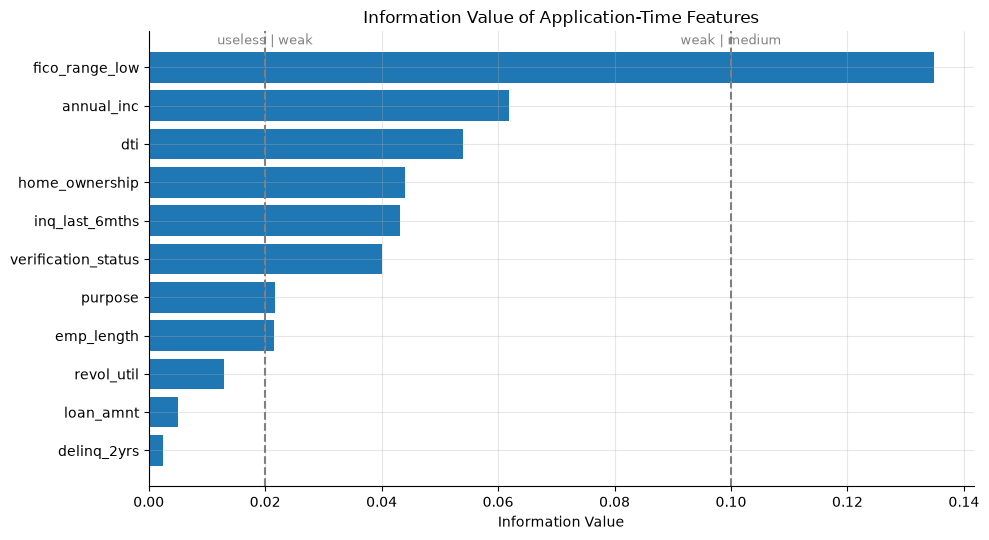

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.5))
plot_df = ranking.sort_values("iv")
ax.barh(plot_df["feature"], plot_df["iv"])
for x, label in [(0.02, "useless | weak"), (0.1, "weak | medium")]:
    ax.axvline(x, linestyle="--", color="gray")
    ax.annotate(label, (x, len(plot_df) - 0.4), ha="center", fontsize=9, color="gray")
ax.set_title("Information Value of Application-Time Features")
ax.set_xlabel("Information Value")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "iv_by_feature.png", dpi=150)
plt.show()

**Shortlist for modeling (8):** FICO, income, DTI, home ownership, inquiries, verification status, purpose, employment length. Revolving utilization (0.013) is kept under review: it is a well-known risk driver, and its weak IV may reflect the quantile binning. Loan amount and past delinquencies are dropped.

## 6. Development vs. out-of-time sample
A random split would mix 2014 and 2015 loans and hide changes over time. An **out-of-time (OOT)** sample tests the model the way it will be used: trained on the past, applied to the future.

In [7]:
con.sql("""
SELECT CASE WHEN issue_date < '2015-07-01' THEN 'development' ELSE 'oot' END AS sample,
       MIN(issue_date)                                    AS first_issue,
       MAX(issue_date)                                    AS last_issue,
       COUNT(*)                                           AS n_loans,
       ROUND(COUNT(*) * 1.0 / SUM(COUNT(*)) OVER (), 4)   AS pct_loans,
       ROUND(AVG(bad_flag), 4)                            AS bad_rate
FROM cohort
GROUP BY sample
ORDER BY sample
""").df()

,sample,first_issue,last_issue,n_loans,pct_loans,bad_rate
0,development,2014-01-01,2015-06-01,283361,0.6357,0.1432
1,oot,2015-07-01,2015-12-01,162382,0.3643,0.1474


The development sample will be split again at random (80% train, 20% validation), giving roughly **51% / 13% / 36%** overall. Why not train on 2014 and test on 2015? The grade view below shows the drift.

In [8]:
drift = con.sql("""
SELECT grade,
       ROUND(COUNT(*) FILTER (YEAR(issue_date) = 2014) * 1.0
             / SUM(COUNT(*) FILTER (YEAR(issue_date) = 2014)) OVER (), 3)  AS share_2014,
       ROUND(COUNT(*) FILTER (YEAR(issue_date) = 2015) * 1.0
             / SUM(COUNT(*) FILTER (YEAR(issue_date) = 2015)) OVER (), 3)  AS share_2015,
       ROUND(AVG(bad_flag) FILTER (YEAR(issue_date) = 2014), 4)            AS bad_rate_2014,
       ROUND(AVG(bad_flag) FILTER (YEAR(issue_date) = 2015), 4)            AS bad_rate_2015
FROM cohort
GROUP BY grade
ORDER BY grade
""").df()
drift

,grade,share_2014,share_2015,bad_rate_2014,bad_rate_2015
0,A,0.217,0.248,0.0538,0.0543
1,B,0.329,0.324,0.1072,0.1192
2,C,0.271,0.274,0.1719,0.1946
3,D,0.126,0.116,0.2217,0.2624
4,E,0.043,0.033,0.2703,0.3285
5,F,0.012,0.005,0.2949,0.4248
6,G,0.001,0.001,0.3631,0.4612


* **Mix improved** in 2015 (more grade A, fewer D–G), yet **bad rates rose within almost every grade** (F: 29.5% → 42.5%). This is a **rate** shift, i.e. **population drift**.
* A model trained only on 2014 would **underestimate** 2015 defaults. Training on data through Jun-2015 narrows the development–OOT bad-rate gap from 1.2 pp (2014 vs. 2015) to 0.4 pp.

## 7. Next steps
* Check **correlations** among the shortlisted features (e.g. income vs. DTI) before modeling.
* Fit a **logistic-regression scorecard** on WOE-transformed features; compare against `grade` on the OOT sample (KS, AUC / Gini, calibration).
* *Caveat: IV depends on the binning and ignores interactions between features.*